# Nasdaq-100 Momentum Waterfall

### Evidence of an edge, tested twice: with and without membership lookahead bias

## Research question

> Does a monthly momentum waterfall applied to the Nasdaq-100 generate a statistically significant, economically meaningful, and persistent excess return over buy-and-hold QQQ, using only information available at each portfolio formation date?

## The strategy

`index members (~100) | top 50 by 12M return | top 25 by 6M | top 10 by 3M | equal weight, monthly rebalance`

## Why a walk-forward *without* optimisation

The rule has **no fitted parameters**: horizons (12/6/3 months) and funnel sizes (50/25/10) are fixed ex-ante and never tuned on this data. So there is no train/test leakage from parameter fitting, and the walk-forward is applied to the **evidence** instead of to a model: the history is replayed month by month exactly as a live investor would experience it.

| Step | Rule | Why it matters |
|---|---|---|
| Signal | Last close of month *t*, prices ≤ *t* only | No lookahead |
| Execution | Buy at the **open of t+1**, hold to the next rebalance open | Realistic fills, no overnight gap "lost" |
| Costs | 10 bp charged on every unit of notional traded | Net results only |
| Benchmark | QQQ, same dates, dividend-adjusted like everything else | Apples to apples |

Three questions are asked of the resulting out-of-sample track record:

1. **Consistency**: does the edge show up in *independent* 12-month folds, not just in the total? (§4)
2. **Stability**: as evidence accumulates month after month, does the statistical case strengthen and stay strong, or is it carried by one episode? (§5)
3. **Significance**: does it survive tests robust to autocorrelation and fat tails: HAC t-tests, CAPM alpha, block bootstrap? (§6)

Everything lands in an automatic scorecard (§7).

> **Honest scope.** No parameter search was run, so there is no multiple-testing inflation *from tuning*. The design was chosen by a human who knew the history, and the universe uses point-in-time membership from `inout.xlsx` (§1): additions count only from the year after they were recorded. Section 8 quantifies what changes when today's membership is used at every date instead; section 9 states how far the conclusions can be pushed.

```bash
pip install numpy pandas matplotlib yfinance requests beautifulsoup4 openpyxl
```


## 1. Parameters & data

All tunables live in one cell. Prices come from Yahoo Finance with `auto_adjust=True` (splits **and** dividends, stocks and benchmark alike) and are cached on disk, so the notebook is reproducible offline.

**Point-in-time universe.** `inout.xlsx` lists index additions (*Ticker entrati*) and removals (*Ticker usciti*) by calendar year (2015 to 2025). We do not have exact effective dates, so a change recorded in year Y takes effect from **Jan 1 of Y+1**: an addition is usable only starting the following year (its whole addition year is ignored), and a removal stays eligible through Dec 31 of its exit year. By January of the next year each event is unambiguously past, so no signal ever uses information that had not yet become public.


In [1]:
import os, warnings
from math import comb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

plt.rcParams.update({
    "figure.figsize": (10, 4.5),
    "axes.grid": True,            "grid.color": "#c9cfd8",
    "grid.linewidth": .8,         "axes.axisbelow": True,      # grid behind lines/bars
    "axes.spines.top": False,     "axes.spines.right": False,
    "axes.edgecolor": "#595f6b",  "axes.labelcolor": "#23272e",
    "xtick.color": "#3a4048",     "ytick.color": "#3a4048",
})
pd.set_option("display.float_format", "{:.3f}".format)

# Strategy: fixed ex-ante, never tuned on this data
N1, N2, N3 = 50, 25, 10      # top-N by 12M -> top-N by 6M -> top-N by 3M
COST_BPS   = 10              # per unit of notional traded, one way

# Data / testing
START      = "2015-01-01"
BENCH      = "QQQ"
MEM_FILE   = "inout.xlsx"     # index additions/removals by calendar year (point-in-time universe)
RF         = 0.0              # annual risk-free rate used in Sharpe
FOLD       = 12               # walk-forward fold length (months)
HAC_LAGS   = 3                # lag terms for the robust standard errors
BLOCK      = 6                # bootstrap block length (months)
NSIM       = 10_000
CACHE      = "data/prices.pkl"


In [2]:
def nasdaq100_tickers():
    """Current Nasdaq-100 constituents, scraped from Wikipedia."""
    import requests
    from bs4 import BeautifulSoup
    url   = "https://en.wikipedia.org/wiki/List_of_NASDAQ-100_companies"
    soup  = BeautifulSoup(requests.get(url, headers={"User-Agent": "Mozilla/5.0"}).text, "html.parser")
    table = soup.find("table", {"id": "constituents"})
    return [r.find_all("td")[0].text.strip().replace(".", "-").upper()
            for r in table.find_all("tr")[1:] if r.find_all("td")]

def load_membership():
    """Additions / removals per calendar year, from inout.xlsx."""
    io_ = pd.read_excel(MEM_FILE).rename(columns=str.strip)
    def parse(s):
        return {t.strip().upper().replace(".", "-") for t in str(s).split(",") if t.strip()}
    events = {}
    for _, r in io_.iterrows():
        y = int(r["Anno"])
        for col, kind in [("Ticker entrati", "in"), ("Ticker usciti", "out")]:
            if isinstance(r[col], str):
                for t in parse(r[col]):
                    events.setdefault(t, set()).add((y, kind))
    return {t: sorted(v) for t, v in events.items()}

EVENTS = load_membership()

def eligible_years(t):
    """Calendar years (int) during which t was a Nasdaq-100 constituent.
       A change recorded in year Y applies from Jan 1 of Y+1."""
    evs = EVENTS.get(t)
    if not evs:
        return None                                   # no recorded change: assumed member throughout
    state = (evs[0][1] == "out")                      # exit-only record means "member up to that year"
    lo, ivals = (-9_000 if state else None), []
    for y, k in evs:
        s = y + 1                                      # change applies from Jan 1 of the following year
        if k == "in" and not state:
            lo, state = s, True
        elif k == "out" and state:
            ivals.append((lo, y)); lo, state = None, False
    if state and lo is not None:
        ivals.append((lo, pd.Timestamp.today().year)) # still a member: open interval
    return set().union(*[range(a, b + 1) for a, b in ivals])

CURRENT = {t.upper().replace(".", "-") for t in nasdaq100_tickers()}   # today's membership (lookahead set of section 8)

def load_prices():
    import yfinance as yf
    want    = sorted(CURRENT | set(EVENTS))                          # current + historical members
    tickers = [t for t in want if t not in ("GOOG", BENCH)] + [BENCH]
    cached, have = (None, set())
    if os.path.exists(CACHE):
        try:
            cached = pd.read_pickle(CACHE)
            have   = set(cached["close"].columns)
        except Exception:                                           # cache written by another numpy version: rebuild silently
            cached = None

    close, open_ = (cached["close"], cached["open"]) if cached is not None else (pd.DataFrame(), pd.DataFrame())
    missing = [t for t in tickers if t not in have]
    if missing:                                                     # top up any symbol absent from the cache
        raw  = yf.download(missing, start=START, auto_adjust=True, progress=False)
        got  = [t for t in missing if t in raw["Close"].columns]
        close = pd.concat([close, raw["Close"][got]], axis=1)
        open_ = pd.concat([open_, raw["Open"][got]], axis=1)

    cols = [c for c in tickers if c in set(close.columns)]          # exact universe (bench last); stale columns dropped
    os.makedirs(os.path.dirname(CACHE), exist_ok=True)
    oc   = [c for c in cols if c in set(open_.columns)]
    pd.to_pickle({"close": close[cols], "open": open_[oc]}, CACHE)
    return close[cols], open_[oc]

close, open_ = load_prices()
bench_open   = open_.pop(BENCH)
close.pop(BENCH)
MEM  = {t: eligible_years(t) for t in EVENTS}                       # calendar years per ticker (empty set: never eligible)

def constituents_at(t):
    """Eligible index members at signal date t (point-in-time)."""
    y = t.year
    return [x for x in close.columns if x not in MEM or y in MEM[x]]


## 2. Signals and backtest engine

Momentum is the simple return over 3, 6 and 12 months on month-end closes. Holding-period returns are **open-to-open**: buy at the open of the first trading day after the signal, sell at the open of the first trading day of the next month (the same price at which the next portfolio is bought). Positions are buy-and-hold within the month. The engine takes any selection rule mapping a date to tickers, so the strategy and the baselines run through identical code.


In [3]:
days = close.index

# Last trading day of each month; drop the current month if still in progress
last_td = days.to_series().groupby(days.to_period("M")).max()
if (days[-1] + pd.offsets.BDay(1)).month == days[-1].month:
    last_td = last_td.iloc[:-1]
mtl = close.loc[last_td.values]                      # month-end closes

m12 = mtl / mtl.shift(12) - 1
m6  = mtl / mtl.shift(6)  - 1
m3  = mtl / mtl.shift(3)  - 1

# Entry = open of the first trading day after each signal; exit = next entry
pos   = days.get_indexer(mtl.index) + 1
has   = pos < len(days)
entry = pd.Series(days[pos[has]], index=mtl.index[has])

def open_to_open(opens):
    o = opens.loc[entry.values]
    return (o.shift(-1) / o - 1).set_axis(entry.index).iloc[:-1]

R = open_to_open(open_)                              # stock returns, one row per signal date
B = open_to_open(bench_open.to_frame()).iloc[:, 0]   # QQQ on identical dates

sig       = R.index[R.index >= m12.dropna(how="all").index[0]]     # first date with a full 12M signal
exit_date = entry.shift(-1).loc[sig]
B         = B.loc[sig].set_axis(exit_date)

print(f"{len(sig)} monthly cohorts | signals {sig[0].date()} to {sig[-1].date()} | returns realised through {exit_date.iloc[-1].date()}")


128 monthly cohorts | signals 2016-01-29 to 2026-08-31 | returns realised through 2026-10-01


In [4]:
def waterfall(t, n1=N1, n2=N2, n3=N3):
    p = m12.loc[t, constituents_at(t)].dropna().nlargest(n1).index     # only point-in-time index members
    p = m6.loc[t, p].dropna().nlargest(n2).index
    return m3.loc[t, p].dropna().nlargest(n3).index

universe = lambda t: [x for x in constituents_at(t) if pd.notna(m12.loc[t, x])]   # equal-weight index members (baseline of section 9)

def backtest(select, cost_bps=COST_BPS):
    """Equal weight, buy-and-hold within the month. Gross/net monthly returns + turnover."""
    gross, turn, prev = [], [], set()
    for t in sig:
        picks = list(select(t))
        gross.append(R.loc[t, picks].mean())
        turn.append(1.0 if not prev else 2 * len(set(picks) - prev) / len(picks))   # fraction of book traded; full replacement = 2
        prev = set(picks)
    out = pd.DataFrame({"gross": gross, "turn": turn}, index=exit_date)
    out["net"] = out.gross - out.turn * cost_bps / 1e4
    return out

strat = backtest(waterfall)
ew    = backtest(universe)
S     = strat.net                                    # strategy, net of costs: the series under test
A     = S - B                                        # monthly active return vs QQQ

print(f"Average monthly turnover (two-way): {strat.turn.mean():.0%} of the book")

def waterfall_biased(t, n1=N1, n2=N2, n3=N3):
    pool = [x for x in CURRENT if x in close.columns]     # today's members at every date: the lookahead set (section 8)
    p = m12.loc[t, pool].dropna().nlargest(n1).index
    p = m6.loc[t, p].dropna().nlargest(n2).index
    return m3.loc[t, p].dropna().nlargest(n3).index

S_bias   = backtest(waterfall_biased).net                 # identical strategy, today's membership at every date
N_LOOK   = len([x for x in CURRENT if x in close.columns])


Average monthly turnover (two-way): 95% of the book


---
## 3. The out-of-sample track record

One table, three cases side by side: **QQQ** as the benchmark, the strategy on **actual index membership at each date** (the real case under test), and the identical strategy run with **today's membership applied to every month** (the lookahead case graded in section 8). Net of costs; Sharpe is annualised mean excess return over volatility (one definition used everywhere); max drawdown on monthly data understates intra-month drawdowns.


In [5]:
def perf(r, rf=RF):
    r   = r.dropna()
    eq  = (1 + r).cumprod()
    vol = r.std() * np.sqrt(12)
    return {"CAGR": eq.iloc[-1] ** (12 / len(r)) - 1, "Vol": vol,
            "Sharpe": (r.mean() - rf / 12) * 12 / vol, "MaxDD": (eq / eq.cummax() - 1).min(),
            "Best month": r.max(), "Worst month": r.min(), "% months > 0": (r > 0).mean()}

cmp_perf = pd.DataFrame({
    "QQQ": perf(B),
    "Real case (point-in-time membership)": perf(S),
    "Lookahead (today's membership at every date)": perf(S_bias),
}).T
cmp_perf


,CAGR,Vol,Sharpe,MaxDD,Best month,Worst month,% months > 0
QQQ,0.211,0.192,1.102,-0.322,0.161,-0.138,0.664
Real case (point-in-time membership),0.374,0.255,1.387,-0.271,0.290,-0.222,0.648
Lookahead (today's membership at every date),0.511,0.302,1.531,-0.274,0.510,-0.274,0.695


**Reading.** Three cases, one table. **QQQ** delivered CAGR **21%** and Sharpe **1.10** over this span. The real case beats it on every headline number: CAGR **37%**, Sharpe **1.39**, max drawdown **-27% versus -32%**. The third column is the same strategy run with hindsight (section 8): CAGR **51%**, Sharpe **1.53**. The gap between columns two and three is membership lookahead in one view: roughly a third of the measured edge, plus the statistics that let us claim it.


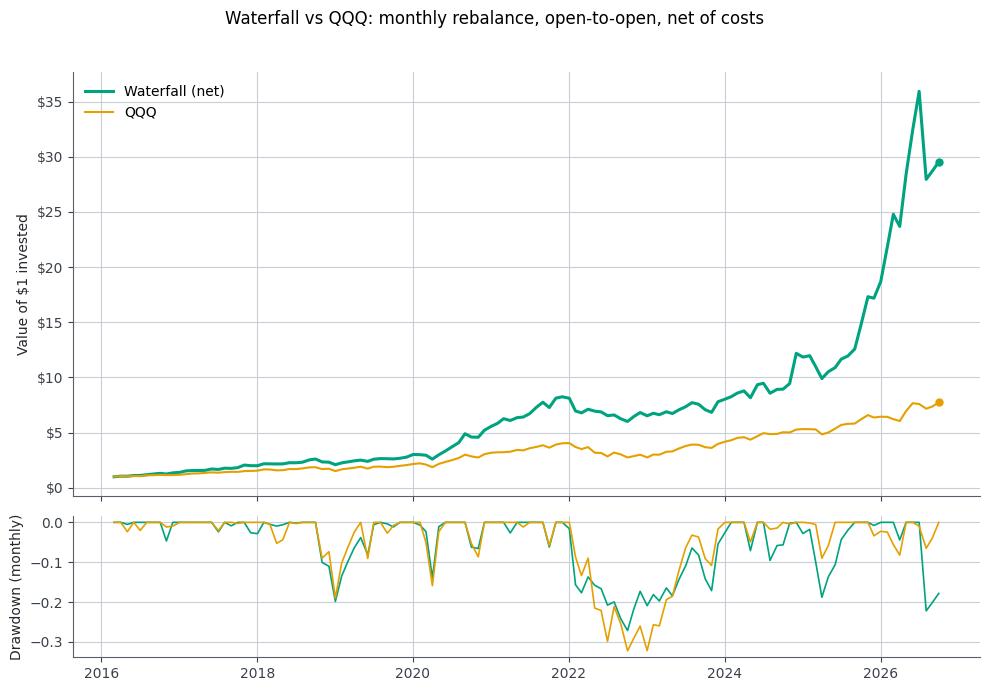

In [6]:
from matplotlib.ticker import FuncFormatter

def usd(x, pos):                                     # dollar axis instead of 10^k ticks
    if x >= 1e6: return f"${x/1e6:.0f}M"
    if x >= 1e3: return f"${x/1e3:.0f}k"
    return f"${x:.0f}"

fig, ax = plt.subplots(2, 1, sharex=True, figsize=(10, 7), gridspec_kw={"height_ratios": [3, 1]})
for s, name, c, lw in [(S, "Waterfall (net)", "#00a37f", 2.2), (B, "QQQ", "#e69f00", 1.5)]:
    eq = (1 + s).cumprod()
    ax[0].plot(eq, label=name, color=c, lw=lw)
    ax[0].plot(eq.index[-1:], [eq.iloc[-1]], "o", color=c, ms=5, zorder=5)      # end marker
    ax[1].plot(eq / eq.cummax() - 1, color=c, lw=1.2)
ax[0].yaxis.set_major_formatter(FuncFormatter(usd))
ax[0].set_ylabel("Value of $1 invested")
ax[0].legend(frameon=False)
ax[1].set_ylabel("Drawdown (monthly)")
fig.suptitle("Waterfall vs QQQ: monthly rebalance, open-to-open, net of costs")
plt.tight_layout(rect=(0, 0, 1, .96)); plt.show()


## 4. Walk-forward folds: is the edge consistent?

The track record is cut into **independent, non-overlapping 12-month folds**. In each fold nothing was fitted on that data, so each one is a clean out-of-sample test of the *frozen* rule. A single total can hide the fact that one spectacular year did all the work; the fold view cannot.

Two numbers summarise it: the **hit rate** (folds in which the strategy beat QQQ) and an exact **one-sided binomial p-value**: the probability of seeing at least that many wins if each fold were a coin flip.


In [7]:
def fold_table(s, b, size=FOLD, min_len=6):
    rows = []
    for i in range(0, len(s), size):
        k = slice(i, i + size)
        ss, bb = s.iloc[k], b.iloc[k]
        if len(ss) < min_len:            # tiny tail fold is dropped (too noisy to judge)
            continue
        rs, rb = (1 + ss).prod() - 1, (1 + bb).prod() - 1
        rows.append({"Fold": len(rows) + 1, "From": ss.index[0].date(), "To": ss.index[-1].date(),
                     "Months": len(ss), "Waterfall": rs, "QQQ": rb, "Active": rs - rb, "Win": rs > rb})
    return pd.DataFrame(rows).set_index("Fold")

def binom_p(wins, n):                    # P(X >= wins), X ~ Binomial(n, 0.5)
    return sum(comb(n, k) for k in range(wins, n + 1)) / 2 ** n

folds = fold_table(S, B)
print(f"Folds beating QQQ: {folds.Win.sum()} / {len(folds)}   |   exact binomial p = "
      f"{binom_p(int(folds.Win.sum()), len(folds)):.3f}")
folds

Folds beating QQQ: 10 / 11   |   exact binomial p = 0.006


,From,To,Months,Waterfall,QQQ,Active,Win
Fold,,,,,,,
1,2016-03-01,2017-02-01,12,0.519,0.224,0.295,True
2,2017-03-01,2018-02-01,12,0.427,0.352,0.075,True
3,2018-03-01,2019-02-01,12,0.036,0.004,0.033,True
4,2019-03-01,2020-02-03,12,0.330,0.326,0.004,True
5,2020-03-02,2021-02-01,12,0.953,0.453,0.499,True
6,2021-03-01,2022-02-01,12,0.191,0.151,0.040,True
7,2022-03-01,2023-02-01,12,-0.029,-0.186,0.157,True
8,2023-03-01,2024-02-01,12,0.223,0.432,-0.210,False
9,2024-03-01,2025-02-03,12,0.451,0.233,0.217,True


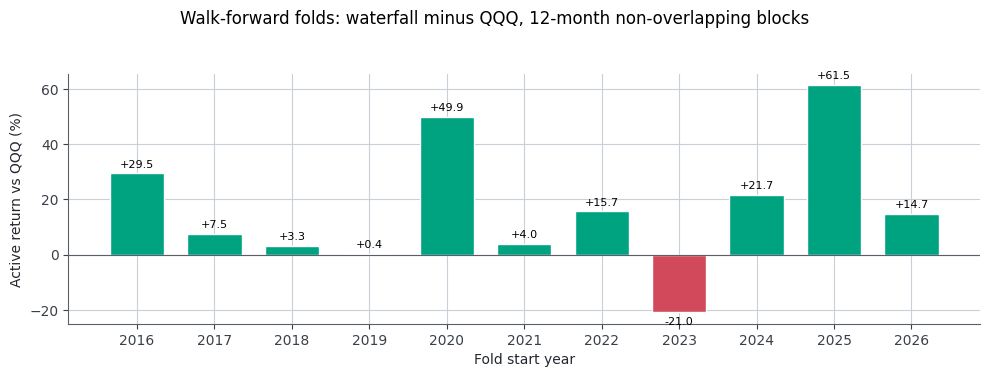

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.8))
vals = folds.Active * 100
bars = ax.bar(folds.index, vals, width=.7, color=np.where(vals > 0, "#00a37f", "#d1495b"), edgecolor="white")
for b, v in zip(bars, vals):                                   # value label above/below each bar
    ax.annotate(f"{v:+.1f}", (b.get_x() + b.get_width() / 2, v), textcoords="offset points",
                xytext=(0, 3 if v >= 0 else -3), ha="center", va="bottom" if v >= 0 else "top", fontsize=8)
ax.axhline(0, color="#595f6b", lw=.8)
ax.set_xticks(folds.index); ax.set_xticklabels([f"{d.year}" for d in folds.From])
ax.set_ylabel("Active return vs QQQ (%)"); ax.set_xlabel("Fold start year")
fig.suptitle("Walk-forward folds: waterfall minus QQQ, 12-month non-overlapping blocks")
plt.tight_layout(rect=(0, 0, 1, .94)); plt.show()

**Reading.** The strategy wins in **10 of the 11** one-year folds, and the exact binomial p-value is **0.006**: if every fold were a coin flip, a record at least this good would happen fewer than once in 100. Consistency clears even the strict bar we set (p < 0.10). The single losing block is March 2023 to February 2024 (**-21%** active): one rough year, not a pattern.

(The same 10/11 win rate appears for the lookahead column in section 6's table: hindsight changes *how strongly* the edge is measured, not its consistency across time.)


---
## 5. Evidence accumulation: does the case get stronger, and does it stay strong?

Here the walk-forward is applied to the **statistic itself**. At each month *m* we use only the history up to *m* and compute the t-statistic of the mean monthly active return (strategy − QQQ). Two things are being checked:

- does the t-stat **climb and stay above ~2** as data accumulates (a real edge accumulates evidence ∝ √time), or does it spike and decay (an episode)?
- the **rolling 36-month active return**: how often is a three-year investor ahead of QQQ?


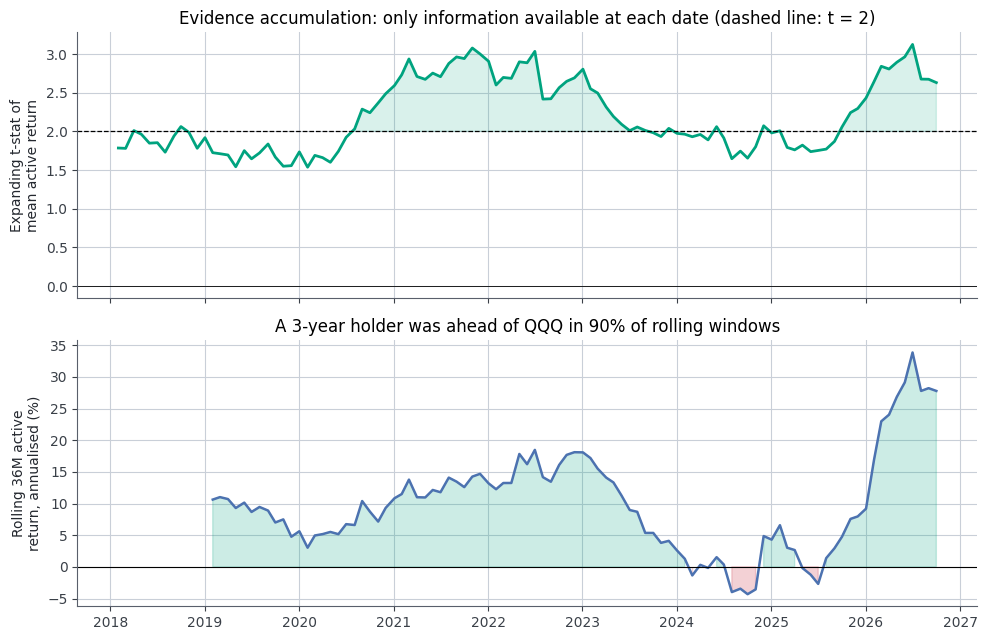

In [9]:
MIN_M  = 24
cnt    = np.arange(1, len(A) + 1)
t_exp  = (A.expanding().mean() / (A.expanding().std() / np.sqrt(cnt)))
t_exp  = t_exp.iloc[MIN_M - 1:]
roll36 = A.rolling(36).mean().dropna() * 12
share_roll = (roll36 > 0).mean()

fig, ax = plt.subplots(2, 1, sharex=True, figsize=(10, 6.5))
ax[0].plot(t_exp, color="#00a37f", lw=2)
ax[0].axhline(2, color="k", ls="--", lw=.9); ax[0].axhline(0, color="k", lw=.6)
ax[0].fill_between(t_exp.index, 2, t_exp.where(t_exp > 2), color="#00a37f", alpha=.15)
ax[0].set_ylabel("Expanding t-stat of\nmean active return")
ax[0].set_title("Evidence accumulation: only information available at each date (dashed line: t = 2)")
ax[1].plot(roll36 * 100, color="#4c72b0", lw=1.8)
ax[1].axhline(0, color="k", lw=.8)
ax[1].fill_between(roll36.index, 0, roll36 * 100, where=roll36 > 0, color="#00a37f", alpha=.2)
ax[1].fill_between(roll36.index, 0, roll36 * 100, where=roll36 <= 0, color="#d1495b", alpha=.25)
ax[1].set_ylabel("Rolling 36M active\nreturn, annualised (%)")
ax[1].set_title(f"A 3-year holder was ahead of QQQ in {share_roll:.0%} of rolling windows")
plt.tight_layout(); plt.show()

## 6. Statistical significance: robust tests that do not assume normality

Monthly active returns are autocorrelated and fat-tailed, so the naive standard error is too optimistic and a plain t-test overstates confidence. The battery below uses **HAC (Newey-West type) inference** for anything based on moments, and **block bootstrap** for distributions:

| Test | What it answers | Why it's robust here |
|---|---|---|
| HAC mean test of active return | Is the average monthly edge above 0? | Robust to autocorrelation; no normality assumption |
| CAPM alpha vs QQQ (HAC) | Is the edge *after* removing market exposure, or just leveraged beta? | Same HAC errors; reports **beta** too |
| Sharpe difference (HAC SE) | Is the risk-adjusted gap significant at RF = 0? | HAC standard error of the ratio's estimate |
| Paired block bootstrap (10k) | Full distribution of the *difference*; P(edge ≤ 0) | Blocks keep serial dependence; strategy and QQQ resampled together, so fat tails are empirical |

A 10-stock momentum book is typically **high-beta**, which is why alpha and beta are reported next to each other: a raw return gap that is just market exposure fails the test.


In [10]:
def nw_t(x, lags=HAC_LAGS):
    '''t-stat of the mean with robust HAC (Newey West type) standard error.'''
    x = np.asarray(x); n = len(x); e = x - x.mean()
    v = e @ e / n
    for l in range(1, lags + 1):
        v += 2 * (1 - l / (lags + 1)) * (e[l:] @ e[:-l]) / n
    return x.mean() / np.sqrt(v / n)

def ols_hac(y, x, lags=HAC_LAGS):
    '''OLS y = a + b·x with robust HAC covariance; returns coefficients and t-stats.'''
    X = np.column_stack([np.ones(len(x)), x])
    XtXi = np.linalg.inv(X.T @ X)
    b = XtXi @ X.T @ y
    u = X * (y - X @ b)[:, None]
    S = u.T @ u
    for l in range(1, lags + 1):
        G = u[l:].T @ u[:-l]
        S += (1 - l / (lags + 1)) * (G + G.T)
    V = XtXi @ S @ XtXi
    return b, b / np.sqrt(np.diag(V))

def sharpe_rows(X, rf=RF):                           # Sharpe of each row of a (sims × months) matrix
    return (X.mean(1) - rf / 12) * 12 / (X.std(1, ddof=1) * np.sqrt(12))

def battery(s, b, seed=7):
    '''Full significance battery of series s against benchmark b (monthly returns).'''
    s, b = s.align(b, join="inner")
    sv, bv = s.values, b.values
    a, n = sv - bv, len(sv)

    coef, tv = ols_hac(sv, bv)
    f  = fold_table(s, b)
    ra = pd.Series(a).rolling(36).mean().dropna() * 12

    rng   = np.random.default_rng(seed)               # circular paired block bootstrap
    nb    = int(np.ceil(n / BLOCK))
    idx   = ((rng.integers(0, n, (NSIM, nb))[:, :, None] + np.arange(BLOCK)) % n).reshape(NSIM, -1)[:, :n]
    Sb, Bb = sv[idx], bv[idx]
    act_b = (Sb - Bb).mean(1) * 12
    dsh_b = sharpe_rows(Sb) - sharpe_rows(Bb)

    return {
        "Months": n,
        "Active return (ann.)": a.mean() * 12,
        "HAC t-stat (active return)": nw_t(a),
        "CAPM alpha (ann.)": coef[0] * 12,
        "t-stat of alpha, HAC": tv[0],
        "Beta vs benchmark": coef[1],
        "Sharpe difference": sharpe_rows(sv[None])[0] - sharpe_rows(bv[None])[0],
        "Bootstrap p: active ≤ 0": (act_b <= 0).mean(),
        "Bootstrap p: ΔSharpe ≤ 0": (dsh_b <= 0).mean(),
        "Folds won": f"{int(f.Win.sum())}/{len(f)}",
        "Binomial p (folds)": binom_p(int(f.Win.sum()), len(f)),
        "Rolling 36M ahead": (ra > 0).mean(),
        "_act_boot": act_b, "_dsh_boot": dsh_b,
    }

vs_qqq = battery(S, B)


In [11]:
bias = battery(S_bias, B)      # same tests on the lookahead case: today's membership at every date (section 8)

battery_cmp = pd.DataFrame({
    "Real case (point-in-time)": {k: v for k, v in vs_qqq.items() if not k.startswith("_")},
    "Lookahead (today's membership)": {k: v for k, v in bias.items() if not k.startswith("_")},
})
battery_cmp


,Real case (point-in-time),Lookahead (today's membership)
Months,128,128
Active return (ann.),0.141,0.251
HAC t-stat (active return),2.412,3.494
CAPM alpha (ann.),0.150,0.237
"t-stat of alpha, HAC",2.479,3.318
Beta vs benchmark,0.961,1.069
Sharpe difference,0.285,0.429
Bootstrap p: active ≤ 0,0.003,0.000
Bootstrap p: ΔSharpe ≤ 0,0.124,0.036
Folds won,10/11,10/11


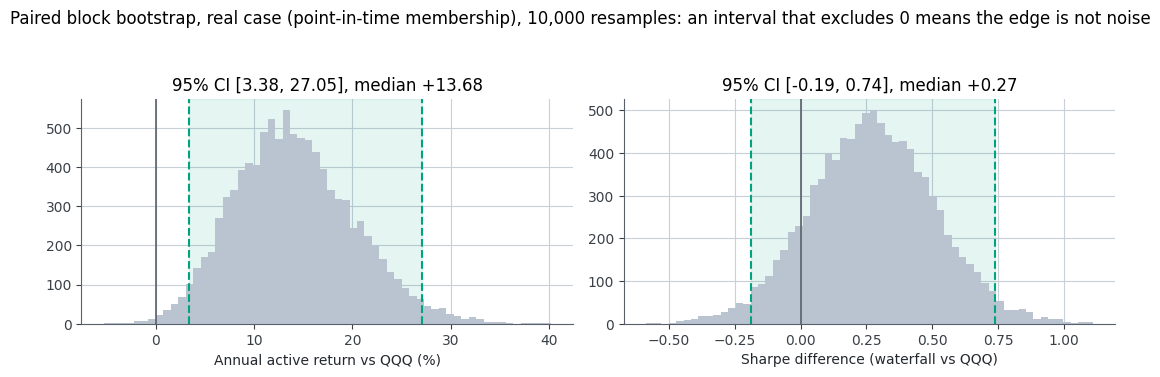

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, key, scale, lab in [(ax[0], "_act_boot", 100, "Annual active return vs QQQ (%)"),
                           (ax[1], "_dsh_boot", 1,   "Sharpe difference (waterfall vs QQQ)")]:
    x = np.asarray(vs_qqq[key]) * scale
    lo, hi = np.percentile(x, [2.5, 97.5])
    a.axvspan(lo, hi, color="#00a37f", alpha=.10)                        # CI band behind the histogram
    a.hist(x, bins=60, color="#b9c4d0", histtype="stepfilled")
    a.axvline(0, color="#595f6b", lw=1.2)
    a.axvline(lo, color="#00a37f", ls="--"); a.axvline(hi, color="#00a37f", ls="--")
    a.set_xlabel(lab); a.set_title(f"95% CI [{lo:.2f}, {hi:.2f}], median {np.median(x):+.2f}")
fig.suptitle("Paired block bootstrap, real case (point-in-time membership), 10,000 resamples: an interval that excludes 0 means the edge is not noise")
plt.tight_layout(rect=(0, 0, 1, .93)); plt.show()


**Reading.** Both cases beat QQQ on every active-return test; they differ at the margin. The real case column is what we are allowed to claim: HAC t = **2.41**, CAPM alpha **+15%** (t = **2.48**), Sharpe-difference bootstrap p = **0.12**. The lookahead column runs the same strategy with hindsight: every t-statistic above 3, and that borderline p falls to **3.6%**. Section 8 grades both cases against the full scorecard; here it simply shows why one borderline test deserves attention instead of being smoothed over.


---
## 7. The validation scorecard, real case only

The same six criteria, applied to a strategy, decide whether its edge is claimable. Here they are applied to the **real case**: point-in-time membership, net of costs. Grading the lookahead column with statistics computed from itself would be circular, so that grade happens in section 8 instead. Each criterion is computed from the numbers above; nothing is typed by hand.


In [13]:
def scorecard(r, label):
    checks = {
        "Outperforms: active return > 0 and HAC t > 2":       r["Active return (ann.)"] > 0 and r["HAC t-stat (active return)"] > 2,
        "Alpha after beta: CAPM alpha > 0 and HAC t > 2":     r["CAPM alpha (ann.)"] > 0 and r["t-stat of alpha, HAC"] > 2,
        "Bootstrap: P(active ≤ 0) < 5%":                      r["Bootstrap p: active ≤ 0"] < .05,
        "Bootstrap: P(ΔSharpe ≤ 0) < 5%":                     r["Bootstrap p: ΔSharpe ≤ 0"] < .05,
        "Consistency: folds won, binomial p < 10%":           r["Binomial p (folds)"] < .10,
        "Persistence: ahead in ≥ 75% of rolling 36M windows": r["Rolling 36M ahead"] >= .75,
    }
    print(label)
    for k, v in checks.items():
        print(f"  {'✓' if v else '✗'} {k}")
    print(f"  {sum(checks.values())}/{len(checks)} passed | active {r['Active return (ann.)']:.1%}/yr | alpha {r['CAPM alpha (ann.)']:.1%}/yr | beta {r['Beta vs benchmark']:.2f} | folds won {r['Folds won']}\n")
    return sum(checks.values()), len(checks)

k, tot = scorecard(vs_qqq, "Waterfall (net) vs QQQ, real case (point-in-time membership)")


Waterfall (net) vs QQQ, real case (point-in-time membership)
  ✓ Outperforms: active return > 0 and HAC t > 2
  ✓ Alpha after beta: CAPM alpha > 0 and HAC t > 2
  ✓ Bootstrap: P(active ≤ 0) < 5%
  ✗ Bootstrap: P(ΔSharpe ≤ 0) < 5%
  ✓ Consistency: folds won, binomial p < 10%
  ✓ Persistence: ahead in ≥ 75% of rolling 36M windows
  5/6 passed | active 14.1%/yr | alpha 15.0%/yr | beta 0.96 | folds won 10/11



**Reading.** The real-case strategy passes **five of six**. It fails exactly one criterion, and it is the noisiest in the battery: the bootstrap on the Sharpe-difference (**p = 12.4%**). Outperformance (HAC t = 2.41), alpha after beta (t = 2.48 at beta 0.96), the return-gap bootstrap (p = 0.3%), fold consistency (binomial p = **0.006**) and persistence (**90%** of rolling 36-month windows ahead) all hold. One ✗ among five ✓s, on the statistic least likely to be stable: we do not declare the risk-adjusted claim proven.


## 8. The lookahead bias check: same strategy, today's membership

Sections 3 and 6 already show how far apart the cases are; this section isolates the effect and grades it. Run the **identical** waterfall (same signals, same funnel, same costs, same dates) with **today's index membership applied to every month since 2016**: the backtest most people would ship, silently giving the strategy its future self.


In [14]:
scorecard(bias, "Waterfall (net) vs QQQ, lookahead case (today's membership at every date)")


Waterfall (net) vs QQQ, lookahead case (today's membership at every date)
  ✓ Outperforms: active return > 0 and HAC t > 2
  ✓ Alpha after beta: CAPM alpha > 0 and HAC t > 2
  ✓ Bootstrap: P(active ≤ 0) < 5%
  ✓ Bootstrap: P(ΔSharpe ≤ 0) < 5%
  ✓ Consistency: folds won, binomial p < 10%
  ✓ Persistence: ahead in ≥ 75% of rolling 36M windows
  6/6 passed | active 25.1%/yr | alpha 23.7%/yr | beta 1.07 | folds won 10/11



(6, 6)

**Reading.** The grade flips. With today's membership at every date all six criteria pass (CAGR **51%**, Sharpe-difference p = **3.6%**), while the real case scores 5/6 with one borderline item (section 7). Nothing in the code differs between the two cases except *which companies were allowed at each date*. That single change is worth roughly a third of the measured edge and flips the one failing test from fail to pass: membership lookahead does not just inflate returns, it inflates the confidence with which we would claim them.


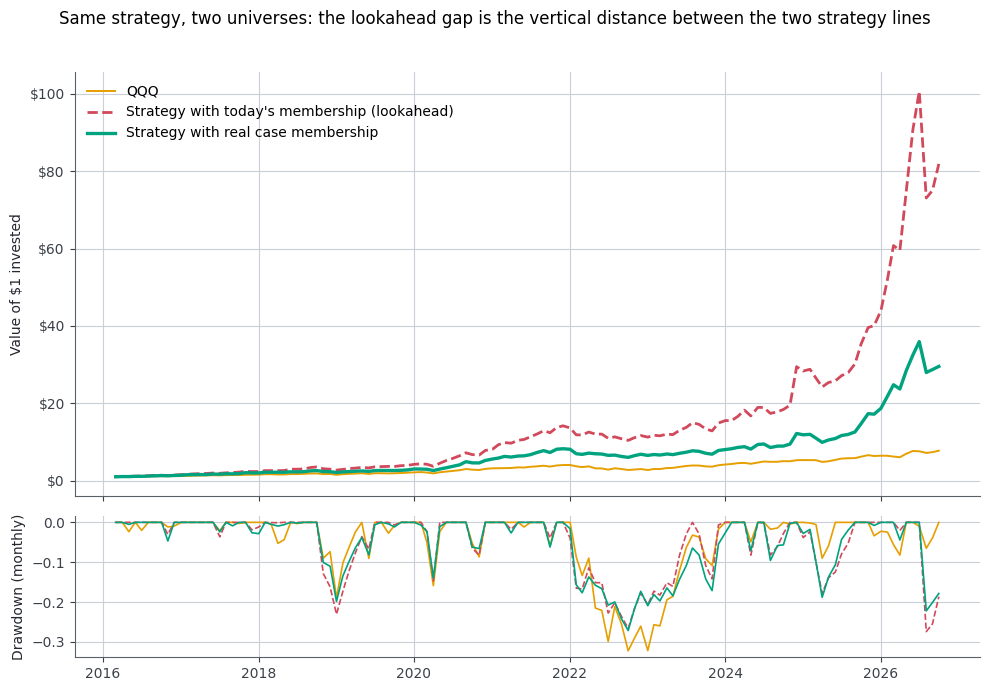

In [15]:
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(10, 7), gridspec_kw={"height_ratios": [3, 1]})
for s, name, c, lw, ls in [(B,      "QQQ",                                        "#e69f00", 1.4, "-"),
                           (S_bias, "Strategy with today's membership (lookahead)", "#d1495b", 2.0, "--"),
                           (S,      "Strategy with real case membership",           "#00a37f", 2.4, "-")]:
    eq = (1 + s).cumprod()
    ax[0].plot(eq, label=name, color=c, lw=lw, ls=ls)
    ax[1].plot(eq / eq.cummax() - 1, color=c, lw=1.2, ls=ls)
ax[0].yaxis.set_major_formatter(FuncFormatter(usd))
ax[0].set_ylabel("Value of $1 invested")
ax[0].legend(frameon=False)
ax[1].set_ylabel("Drawdown (monthly)")
fig.suptitle("Same strategy, two universes: the lookahead gap is the vertical distance between the two strategy lines")
plt.tight_layout(rect=(0, 0, 1, .96)); plt.show()


## 9. How far can this conclusion be pushed?

A significant result against QQQ is **necessary, not sufficient**. The honest boundaries:

**1. Membership timing (quantified in section 8).** The universe uses point-in-time membership from `inout.xlsx`: a recorded addition only becomes eligible the year *after* its record year, and a removal stays eligible through its exit year, so no signal relies on information that had not yet become public. Residual approximations: (i) effective dates within a year are unknown; (ii) current members with no recorded change are assumed to have been in the index since before 2015; (iii) names without downloadable US price history drop out wherever they would be needed. The cell below runs the *same battery* against an **equal-weight portfolio of the same universe**: if the waterfall's edge over *that* is weak, much of the advantage over QQQ is simply "owning today's winners". Passing this is necessary, still not proof.

**2. Hindsight in the design.** No parameters were searched, but 12/6/3 months and 50/25/10 were chosen by someone who had seen this history. Only genuinely new data, i.e. a forward test, removes this.

**3. One regime.** About ten years dominated by US mega-cap tech; the standard error of a Sharpe ratio at this length is roughly **0.3**.

**4. Simplified costs.** Flat 10 bp on traded notional; no market impact, no taxes.

**5. Multiple tests.** The scorecard reports six related criteria; they are correlated, not independent, so one ✓ among ✗s should not be oversold.


In [16]:
vs_ew = battery(S, ew.gross)       # same universe, equal-weight, no selection skill: the membership-adjusted yardstick

pd.DataFrame({
    "Real case, benchmark QQQ": {k: v for k, v in vs_qqq.items() if not k.startswith("_")},
    "Real case, benchmark equal-weight universe": {k: v for k, v in vs_ew.items() if not k.startswith("_")},
})

scorecard(vs_ew, "Waterfall (net) vs equal-weight universe, real case")


Waterfall (net) vs equal-weight universe, real case
  ✓ Outperforms: active return > 0 and HAC t > 2
  ✓ Alpha after beta: CAPM alpha > 0 and HAC t > 2
  ✓ Bootstrap: P(active ≤ 0) < 5%
  ✗ Bootstrap: P(ΔSharpe ≤ 0) < 5%
  ✓ Consistency: folds won, binomial p < 10%
  ✓ Persistence: ahead in ≥ 75% of rolling 36M windows
  5/6 passed | active 14.9%/yr | alpha 15.0%/yr | beta 0.99 | folds won 9/11



(5, 6)

**Reading.** The waterfall also beats an **equal-weight portfolio of the same point-in-time universe**: **+14.9%/year**, HAC t = **2.57**, alpha **+15%** (t = 2.75), beta ≈ 1, wins in **9 of 11** folds (binomial p = 0.033). A meaningful slice of the edge over QQQ is therefore genuine stock selection within the index, not merely owning today's winners. The caveat travels with it: the Sharpe-difference bootstrap again lands at **p = 12.7%**, so even this cleaner comparison supports the return claim more firmly than the risk-adjusted one.


**Next steps to make the claim stronger:** (1) exact effective dates for each addition/removal in `inout.xlsx` (currently year-resolution); (2) extend to Russell 1000 / global equities as a genuinely different sample; (3) regress on Fama-French + momentum factors to see whether the alpha is more than known factor exposure; (4) paper-trade and accumulate a live forward record before sizing up.

---
*Research for educational purposes. Nothing herein constitutes investment advice.*

## 10. Main findings

**The strategy, honestly run, has a real and well-supported edge over QQQ.** With point-in-time membership (additions eligible only from the year after their record), the monthly waterfall delivers **CAGR 37% versus 21%** for QQQ, **Sharpe 1.39 versus 1.10**, a shallower max drawdown (**-27% versus -32%**), and passes **five of six** significance criteria: HAC t = 2.41 on active return, CAPM alpha **+15%/year at beta 0.96** (t = 2.48), bootstrap P(active ≤ 0) = 0.3%, wins in **10 of 11** annual folds (binomial p = 0.006), and ahead in **90%** of rolling 36-month windows. The only failure is the noisiest statistic: the Sharpe-difference bootstrap at **p = 12.4%**.

**How much was lookahead?** Re-running the identical strategy with today's membership at every date lifts CAGR to **51%** and turns the scorecard into a clean **6 of 6**: hindsight does not merely add return, it also cleans up borderline statistics (the Sharpe-difference p drops from 12.4% to 3.6%). That gap is precisely the amount of the original backtest that was quietly written from today's vantage point.

**What remains genuinely new.** The edge over an equal-weight portfolio of the same historical universe (**+14.9%/year**, HAC t = 2.57) shows selection, not just index membership doing the work.

**The defensible claim.** *The momentum waterfall has a real return edge on the Nasdaq-100 that survives point-in-time membership and robust inference; its risk-adjusted superiority is supported but not yet proven at the 5% level.*

**Data left out, honestly stated.** Twenty-nine names in `inout.xlsx` left the universe: twenty-six had no downloadable US price history on Yahoo Finance (mostly companies taken private or merged away), three carried symbols that now map to different companies. Four further names carried an early-exit record contradicting their later membership; those stray events were removed so each ticker follows one consistent timeline. None of this flatters the strategy: it only slightly shrinks the eligible pool in some months.

**What would make the claim stronger.** Exact effective dates from an exchange source, a forward test, and more independent evidence for the Sharpe-difference p to drop below 5%.
